# Pass-01

## Problem Definition


Business problem: estimate a house’s sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load data
house_df= pd.read_csv(url,
               usecols= ['Lot Frontage','SalePrice'])





In [4]:
# look at first and last few rows
print(house_df.head())
print(house_df.tail())

   Lot Frontage  SalePrice
0          62.0     115400
1          72.0      90000
2          50.0     141000
3          68.0     254000
4          60.0     155000
      Lot Frontage  SalePrice
2632          52.0     114500
2633          74.0     162000
2634          61.0     211500
2635          78.0     165000
2636          41.0     225000


In [5]:
# look at shape and size

print(house_df.shape)
print(house_df.size)


(2637, 2)
5274


In [6]:
# display meta data (info)
house_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Lot Frontage  2188 non-null   float64
 1   SalePrice     2637 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 41.3 KB


In [7]:
# display summary statistics
house_df.describe()



,Lot Frontage,SalePrice
count,2188.000000,2637.000000
mean,69.166819,179986.230186
std,23.356779,78309.251522
min,21.000000,12789.000000
25%,58.000000,129500.000000
50%,68.000000,160000.000000
75%,80.000000,213000.000000
max,313.000000,745000.000000


In [8]:
# Columns data types
house_df.dtypes.sort_values()


,0
SalePrice,int64
Lot Frontage,float64


In [9]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [10]:
# look for nulls in target and features
house_df.isnull().sum().sort_values(ascending=False)

,0
Lot Frontage,449
SalePrice,0


In [11]:
# look for nulls in feature in percentage
house_df['Lot Frontage'].isnull().mean() * 100

np.float64(17.02692453545696)

## Data Cleaning


### Backup 1

In [12]:
# make backup
house_df_backup= house_df.copy()

In [13]:
# restore from backup
house_df = house_df_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

### Impute

In [14]:
# Calculate the median
median_frontage = house_df['Lot Frontage'].median()
print(median_frontage)

# Fill nulls with the median
house_df['Lot Frontage']= house_df['Lot Frontage'].fillna(median_frontage)

#verify there are no nulls
house_df.isnull().sum()


68.0


,0
Lot Frontage,0
SalePrice,0


In [15]:
house_df['Lot Frontage'].median()

68.0

## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

In [16]:
# Calculate a correlation matrix for target
house_df.corr() ;

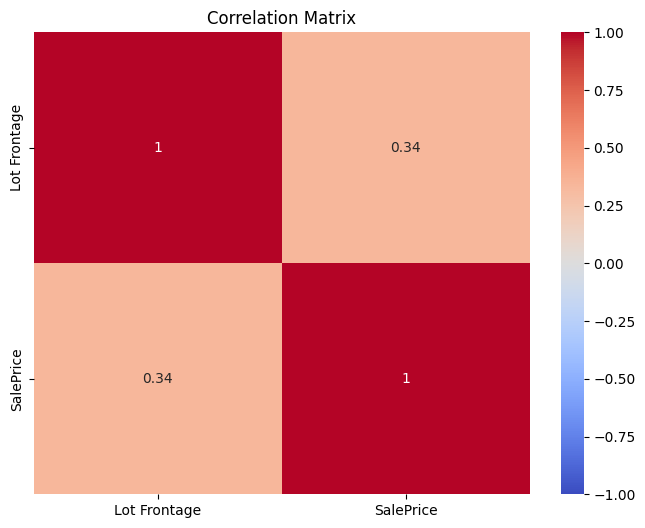

In [17]:
# Display the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(house_df.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()

## Data Visualization


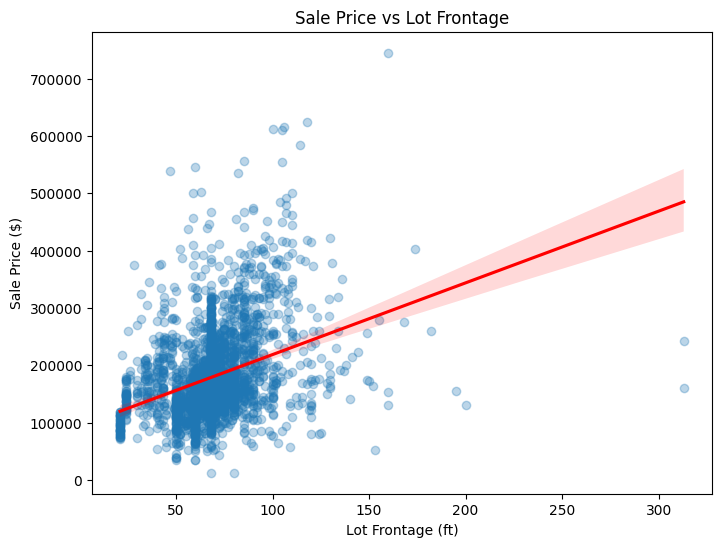

In [18]:
# Scatter plot with a trend line
plt.figure(figsize=(8, 6))
sns.regplot(data=house_df, x='Lot Frontage', y='SalePrice',
            scatter_kws={'alpha': 0.3},   # see-through dots so overlaps show
            line_kws={'color': 'red'})
plt.title('Sale Price vs Lot Frontage')
plt.xlabel('Lot Frontage (ft)')
plt.ylabel('Sale Price ($)')
plt.show()

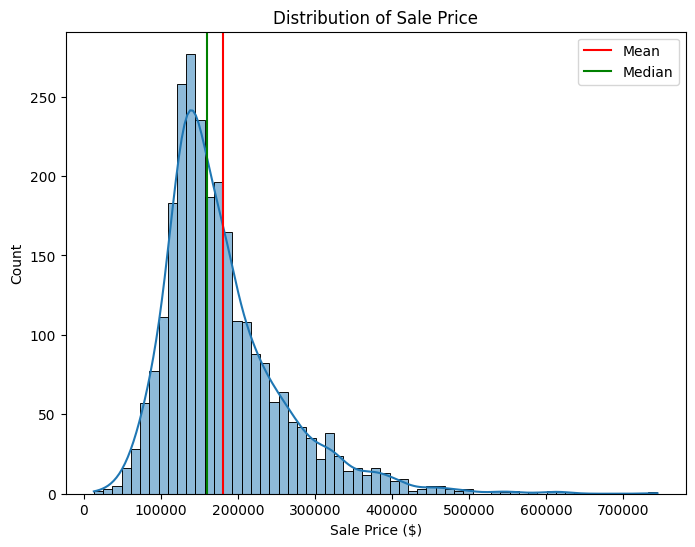

In [20]:
# Histogram of the target with mean and median marked
plt.figure(figsize=(8, 6))
sns.histplot(house_df['SalePrice'], kde=True)
plt.axvline(house_df['SalePrice'].mean(), color='red', label='Mean')
plt.axvline(house_df['SalePrice'].median(), color='green', label='Median')
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price ($)')
plt.legend()
plt.show()

### Summary of Results
- 2,637 houses. Every house has a price.
- Lot Frontage was blank for 449 houses (17%). I filled them with the median (68 ft).
- Lot Frontage and price have a weak positive link (correlation 0.34).
- Lot Frontage alone explains only about 12% of price (0.34 × 0.34 ≈ 0.12).
- A few lots are very wide (up to 313 ft). One sale was very low ($12,789).
- Prices are right-skewed: most houses are cheaper, a few are very expensive.
- Next: use Lot Frontage to build a simple model (Pass 04).